# Экзаменационная задача №19. Подготовка и защита бюджета ИТ-проекта (итоговая задача)

**Дисциплина:** Экономика информатизации, лекция №20
**Студент:** Грошев Степан Сергеевич, группа БИ 5-1
**Дата:** 2026-11-12

In [1]:
# ======================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №19: ПОДГОТОВКА И ЗАЩИТА БЮДЖЕТА ИТ-ПРОЕКТА (ИТОГОВАЯ ЗАДАЧА)
# ======================================================================
# Дисциплина: Экономика информатизации (лекция №20)
# Дата: 2026-11-12
# Студент: Грошев Степан Сергеевич
# Группа: БИ 5-1
# ======================================================================

# Подключение библиотек и общих утилит проекта
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # корень репозитория: utils/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.calculations import npv, irr, payback_period, discounted_payback_period, present_values, annuity_factor, fmt_rub
from utils.visualization import setup_style, thousands_axis, bar_labels, tornado, PALETTE
setup_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", " "))
pd.set_option("display.width", 140)

## 1. Экономическая постановка задачи

Итоговая задача курса: подготовить и **защитить** бюджет внедрения BI-системы (затраты 50 млн руб., экономия 15 млн руб.
в год, срок 5 лет, ставка 10 %). Защита бюджета это не только расчёт, но и умение объяснить ценность проекта
каждой аудитории на её языке и заранее подготовить ответы на возражения с опорой на цифры.

**Цель:** посчитать NPV и сроки окупаемости, оценить риски в цифрах, предложить структуру презентации,
аргументы для разных аудиторий и ответы на возражения.

**Связь с курсом:** NPV и окупаемость (лекция №8), TCO (№7), неопределённость и ценность информации (№15),
реальные опционы (№16), обоснование бюджета (№18). В отличие от задачи №17, здесь упор на оценку риска
методом Монте-Карло и на ответы на возражения.

## 2. Исходные данные

In [2]:
I = 50.0; S = 15.0; H = 5; r = 0.10
pd.DataFrame({"Параметр": ["Затраты (год 0)", "Экономия", "Горизонт", "Ставка дисконтирования"],
              "Значение": ["50 млн руб.", "15 млн руб./год", "5 лет", "10%"]})

,Параметр,Значение
0,Затраты (год 0),50 млн руб.
1,Экономия,15 млн руб./год
2,Горизонт,5 лет
3,Ставка дисконтирования,10%


**Допущения:** затраты разово в году 0, экономия поровну в конце каждого года с 1 по 5, налоги не учитываем.
Ежегодные затраты на владение BI либо уже вычтены из экономии (основной расчёт), либо считаются отдельно (анализ рисков).
Для Монте-Карло: реальная экономия имеет треугольное распределение (9; 15; 18) млн руб., потому что у ИТ-проектов
результат чаще оказывается хуже плана, чем лучше. Затраты тоже треугольные (47,5; 50; 60): перерасход вероятнее экономии.

## 3. Математическая модель

$$NPV = -I + S\cdot\frac{1-(1+r)^{-H}}{r},\qquad PP = \frac{I}{S},\qquad DPP = \frac{-\ln\!\big(1 - \frac{I\,r}{S}\big)}{\ln(1+r)}$$
Порог безубыточности: $S^* = I\cdot\dfrac{r}{1-(1+r)^{-H}}$, $I^* = S\cdot\dfrac{1-(1+r)^{-H}}{r}$.
Риск: $P(NPV<0)$ и VaR$_{5\%}$ по 100 000 испытаний Монте-Карло.

## 4. Реализация расчёта
### 4.1. Ключевые показатели

In [3]:
cf = np.array([-I] + [S] * H)
af = annuity_factor(r, H)
NPV_ = npv(cf, r); PP_ = payback_period(cf); DPP_ = discounted_payback_period(cf, r)
DPP_formula = -math.log(1 - I * r / S) / math.log(1 + r)
S_star = I / af; I_star = S * af
kpi = pd.DataFrame({"Показатель": ["Коэффициент аннуитета (10%, 5 лет)", "PV экономии", "NPV", "IRR", "ROI (5 лет, без дисконта)",
                                   "Простой срок окупаемости", "Дисконтированный срок окупаемости", "Безубыточная экономия S*", "Максимальные затраты I*"],
                    "Значение": [f"{af:.4f}", f"{S*af:.2f} млн", f"{NPV_:.2f} млн", f"{irr(cf):.1%}", f"{(S*H-I)/I:.0%}",
                                 f"{PP_:.2f} года", f"{DPP_:.2f} года (по формуле {DPP_formula:.2f})", f"{S_star:.2f} млн/год ({S_star/S-1:+.0%})", f"{I_star:.2f} млн ({I_star/I-1:+.0%})"]})
kpi

,Показатель,Значение
0,"Коэффициент аннуитета (10%, 5 лет)",3.7908
1,PV экономии,56.86 млн
2,NPV,6.86 млн
3,IRR,15.2%
4,"ROI (5 лет, без дисконта)",50%
5,Простой срок окупаемости,3.33 года
6,Дисконтированный срок окупаемости,4.26 года (по формуле 4.25)
7,Безубыточная экономия S*,13.19 млн/год (-12%)
8,Максимальные затраты I*,56.86 млн (+14%)


### 4.2. Оценка риска в цифрах

In [4]:
rng = np.random.default_rng(20)
N = 100_000
S_sim = rng.triangular(9, 15, 18, N)
I_sim = rng.triangular(47.5, 50, 60, N)
npv_sim = -I_sim + S_sim * af
risk = pd.Series({"Среднее NPV, млн": npv_sim.mean(), "Медиана NPV, млн": np.median(npv_sim), "P(NPV < 0)": (npv_sim < 0).mean(),
                  "VaR 5% (худшие 5% исходов), млн": np.quantile(npv_sim, 0.05), "P95, млн": np.quantile(npv_sim, 0.95)}, name="Значение")
display(risk.round(3).to_frame())

# Торнадо: ±20% по ключевым параметрам
def npv_of(I_=I, S_=S, H_=H, r_=r, opex=0.0):
    return -I_ + (S_ - opex) * annuity_factor(r_, H_)
params = {"Экономия ±20%": ("S_", S * 0.8, S * 1.2), "Затраты ±20%": ("I_", I * 1.2, I * 0.8),
          "Ставка 8% / 12%": ("r_", 0.12, 0.08), "Горизонт 4 / 6 лет": ("H_", 4, 6), "Текущие затраты 2 / 0 млн": ("opex", 2.0, 0.0)}
torn = pd.DataFrame([{"Фактор": k, "NPV (неблаг.)": npv_of(**{p: lo}), "NPV (благ.)": npv_of(**{p: hi})} for k, (p, lo, hi) in params.items()])
torn.round(2)

,Значение
"Среднее NPV, млн",0.61
"Медиана NPV, млн",1.22
P(NPV < 0),0.44
"VaR 5% (худшие 5% исходов), млн",-12.77
"P95, млн",12.25


,Фактор,NPV (неблаг.),NPV (благ.)
0,Экономия ±20%,-4.51,18.23
1,Затраты ±20%,-3.14,16.86
2,Ставка 8% / 12%,4.07,9.89
3,Горизонт 4 / 6 лет,-2.45,15.33
4,Текущие затраты 2 / 0 млн,-0.72,6.86


In [5]:
# Поэтапное внедрение как реальный опцион: пилот 12 млн, через год — решение о продолжении (38 млн)
p_good = 0.6     # вероятность, что пилот подтвердит экономию ≥15 (иначе фактическая экономия 9 и проект останавливается)
npv_full_good = -I + 15 * af; npv_full_bad = -I + 9 * af
staged_good = -12 + 15 * 0.3 / 1.1 - 38 / 1.1 + 15 * annuity_factor(r, 4) / 1.1        # пилот даёт 30% эффекта в 1-й год
staged_bad = -12 + 9 * 0.3 / 1.1 + 9 * 0.3 * annuity_factor(r, 4) / 1.1                 # остаёмся на пилоте
stage = pd.DataFrame({"Сразу всё (50 млн)": [npv_full_good, npv_full_bad, p_good * npv_full_good + (1 - p_good) * npv_full_bad],
                      "Поэтапно (пилот 12 + 38)": [staged_good, staged_bad, p_good * staged_good + (1 - p_good) * staged_bad]},
                     index=["Хороший исход (экономия 15)", "Плохой исход (экономия 9)", f"Ожидаемый NPV (p = {p_good})"])
stage.round(2)

,Сразу всё (50 млн),Поэтапно (пилот 12 + 38)
Хороший исход (экономия 15),6.86,0.77
Плохой исход (экономия 9),-15.88,-1.76
Ожидаемый NPV (p = 0.6),-2.24,-0.24


## 5. Визуализация результатов

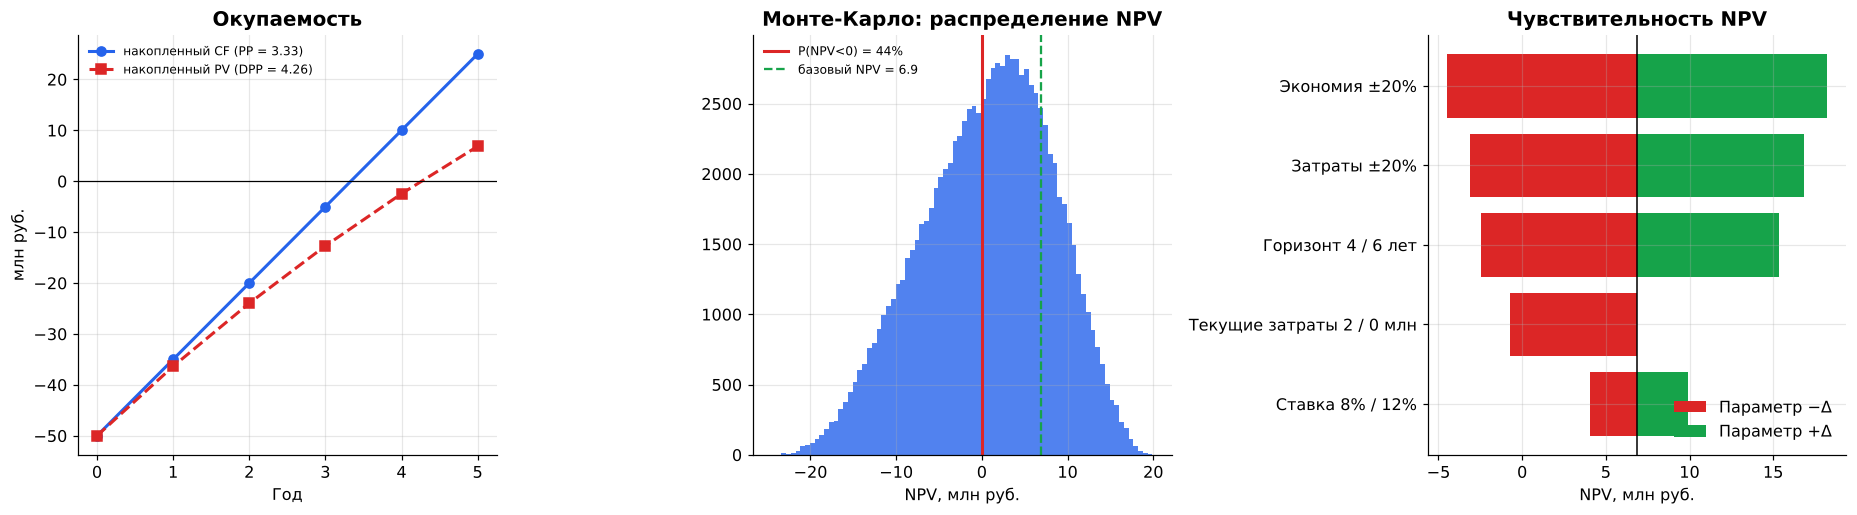

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ax = axes[0]
pv_cum = present_values(cf, r).cumsum()
ax.plot(range(H + 1), cf.cumsum(), "o-", lw=2, label=f"накопленный CF (PP = {PP_:.2f})")
ax.plot(range(H + 1), pv_cum, "s--", lw=2, label=f"накопленный PV (DPP = {DPP_:.2f})")
ax.axhline(0, color="black", lw=0.8); ax.set_xlabel("Год"); ax.set_ylabel("млн руб."); ax.set_title("Окупаемость"); ax.legend(fontsize=8)
ax = axes[1]
ax.hist(npv_sim, bins=80, color=PALETTE[0], alpha=0.8)
ax.axvline(0, color=PALETTE[1], lw=2, label=f"P(NPV<0) = {(npv_sim<0).mean():.0%}")
ax.axvline(NPV_, color=PALETTE[2], ls="--", label=f"базовый NPV = {NPV_:.1f}")
ax.set_xlabel("NPV, млн руб."); ax.set_title("Монте-Карло: распределение NPV"); ax.legend(fontsize=8)
ax = axes[2]
tornado(ax, list(torn["Фактор"]), torn["NPV (неблаг.)"], torn["NPV (благ.)"], NPV_, "Чувствительность NPV", "NPV, млн руб.")
plt.tight_layout(); plt.show()

## 6. Интерпретация результатов

- **NPV около 6,9 млн руб.**, IRR около 15,2 %, простой срок окупаемости **3,33 года**, дисконтированный **около 4,3 года**.
  Проект окупается в пределах срока, но только в последний год.
- **Запас маленький:** проект в плюсе, если экономия не меньше 13,2 млн руб. в год (всего на 12 % ниже плана)
  или затраты не больше 56,9 млн руб. (перерасход до 14 %).
- **При реальных отклонениях риск высокий:** если экономия и затраты чаще отклоняются в худшую сторону, шанс отрицательного NPV
  около половины, а средний NPV близок к нулю. Базовые 6,9 млн руб. это оптимистичная точечная оценка.
- **Внедрение по этапам** (пилот 12 млн руб. и решение о продолжении через год) это плата за информацию. В хорошем случае
  NPV ниже (около 0,8 млн вместо 6,9 млн руб., полный эффект приходит на год позже), зато в плохом случае убыток
  всего около 1,8 млн руб. вместо 15,9 млн. Ожидаемый NPV поэтапного варианта выше примерно на 2 млн руб.,
  а риск крупного убытка почти исчезает. Это главный аргумент на защите.

## 7. Выводы и рекомендации: материалы для защиты

### 7.1. Структура презентации (10–12 минут)
1. **Зачем** (1 слайд): ручная отчётность, решения «на глаз», цена задержек.
2. **Что предлагаем** (1): BI-платформа, охват, сроки.
3. **Сколько стоит и что даёт** (2): бюджет 50 млн руб., экономия 15 млн руб. в год с расшифровкой; NPV 6,9 млн, окупаемость 3,3 года.
4. **Риски честно** (1): порог безубыточности, Монте-Карло, главные риски.
5. **Как снижаем риск** (1): деньги по этапам, пилот, KPI, проверка после внедрения.
6. **План и контрольные точки** (1). 7. **Что просим** (1): одобрить пилот 12 млн руб. и рамочный бюджет.

### 7.2. Аргументы для разных аудиторий
| Аудитория | О чём говорить | Главная мысль |
|---|---|---|
| Финансовая служба | NPV, IRR, окупаемость, риск | IRR 15 % больше ставки 10 %; этапы ограничивают потери в плохом сценарии (−1,8 млн вместо −15,9 млн) |
| Топ-менеджмент | стратегия, скорость решений, контроль | вся картина бизнеса на свежих данных, решения за дни, а не за недели |
| Руководители подразделений | время и удобство | меньше рутины с отчётами, отчёты без очереди к ИТ |
| ИТ | архитектура, нагрузка, поддержка | одно хранилище, стандарты данных, меньше разовых выгрузок |
| Контроль, аудит, безопасность | прозрачность, безопасность | один источник данных, доступ по ролям, журнал действий |

### 7.3. Ответы на возражения
| Возражение | Ответ (с опорой на расчёт) |
|---|---|
| «15 млн экономии слишком оптимистично» | Согласны, поэтому просим только пилот: он покажет реальную экономию. Проект в плюсе до 13,2 млн в год |
| «Окупаемость 3,3 года это долго» | Для инфраструктурных ИТ-проектов это нормально. BI служит 5–7 лет, на 7 годах NPV около 23 млн руб. |
| «Не учли затраты на поддержку» | Учли в анализе: при 2 млн руб. в год NPV около −0,7 млн. Компенсируем облачной подпиской и отечественной платформой |
| «Риск перерасхода» | Фиксированная цена контракта, резерв под контролем комитета, приёмка по этапам; проект в плюсе до 56,9 млн |
| «Можно обойтись Excel» | Excel не масштабируется, нет единых данных и контроля доступа. Ручной труд как раз и есть источник экономии |
| «Сейчас не время, отложим» | Каждый год отсрочки это минус около 15 млн руб. экономии. Пилот дёшево даёт информацию для решения (лекция №15) |
| «Нет гарантий, что будут пользоваться» | KPI использования (активные пользователи, доля отчётов из BI) в целях руководителей, обучение в бюджете |

**Итог:** защищаем не «50 млн руб. сразу», а **пилот за 12 млн руб. с понятными условиями перехода** к полному внедрению.
Так меньше риск для организации, и финансовой службе проще сказать «да».